# Model 2 v2 – 06 Train balanced (MobileNetV3-Large + DeiT-Small)
**What changes vs v1 (notebooks 02/03):** (1) data = v1 + new LEG images (notebook 05); (2) **balanced sampling**:
each batch ≈ 40% HAND, 40% LEG, 20% OTHER, and inside each group rare regions are drawn more often (√ frequency),
with a plain loss (no class weights, to avoid correcting twice); (3) extra augmentation for the real-world
failures: thin strips / letterbox, bright metal-like shapes (plates, screws), perspective, soft glare.
Everything else is identical: models, optimiser, schedule, epochs, best epoch by validation macro-F1.
**Outputs:** outputs/model2_v2/{mobilenetv3,deit_small}_model2v2_best.pt, preds_*_{val,test,newtest}.csv

In [3]:
# ===== SETTINGS =====
from pathlib import Path
DRIVE_ROOT = Path('/content/drive/MyDrive/Research')
OUT_DIR    = DRIVE_ROOT / 'outputs' / 'model2_v2'
MANIFEST, CACHE = OUT_DIR / 'manifest_split_v2.csv', OUT_DIR / 'cache_224_v2.npz'

SEED, IMG_SIZE, BATCH_SIZE = 42, 224, 64
EPOCHS, LR, PATIENCE = 15, 1e-4, 4
P_LOWRES, P_JPEG = 0.3, 0.3                                   # as v1
P_STRIP, P_METAL, P_GLARE, P_PERSP = 0.15, 0.15, 0.15, 0.3     # new real-world augmentations
MASS = {'HAND': 0.4, 'LEG': 0.4, 'OTHER': 0.2}                 # share of each group in every batch
MODELS = {'mobilenetv3': 'torchvision', 'deit_small': 'deit_small_patch16_224.fb_in1k'}

In [4]:
!pip install -q timm
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, random, timm, time, os, io, json
device = 'cuda'
df = pd.read_csv(MANIFEST)
cache = np.load(CACHE, allow_pickle=True); X = cache['images']
assert (cache['paths'][df.cache_idx] == df.path).all(), 'Manifest and cache do not match!'
CLASSES = sorted(df.label.unique()); SHORT = {c: c.split(' - ')[0] for c in CLASSES}
SUPER = {c: ('OTHER' if c == 'OTHER' else 'LEG' if SHORT[c] in ('Hip to knee', 'Knee to ankle', 'Foot and ankle') else 'HAND')
         for c in CLASSES}
SUPER_NAMES = ['HAND', 'LEG', 'OTHER']
M = np.array([[SUPER[c] == s for s in SUPER_NAMES] for c in CLASSES], dtype=float)
df['y'] = df.label.map({c: i for i, c in enumerate(CLASSES)})
splits = {s: df[df.split == s].reset_index(drop=True) for s in ['train', 'val', 'test', 'newtest']}
print({s: len(f) for s, f in splits.items()}, '| cache', X.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'train': 2823, 'val': 590, 'test': 519, 'newtest': 130} | cache (4152, 224, 224)


## Step 1 – Balanced sampler and augmentation

In [5]:
from PIL import Image, ImageDraw, ImageFilter
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T

tr = splits['train']; n_c = tr.label.value_counts()
sq = np.sqrt(n_c); sq_sum = sq.groupby(lambda c: SUPER[c]).sum()
w = tr.label.map(lambda c: MASS[SUPER[c]] * sq[c] / sq_sum[SUPER[c]] / n_c[c]).values
eff = pd.Series(w).groupby(tr.label.map(SUPER).values).sum() / w.sum()
print('Training images per group:', tr.label.map(SUPER).value_counts().to_dict())
print('Share of each group in a batch (expected):', eff.round(2).to_dict())

def degrade(img):                                      # as v1
    if random.random() < P_LOWRES:
        s = random.randint(64, 160); img = img.resize((s, s), Image.BILINEAR).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    if random.random() < P_JPEG:
        buf = io.BytesIO(); img.save(buf, format='JPEG', quality=random.randint(30, 90)); img = Image.open(buf).convert('L')
    return img

def real_world(img):                                   # new: the formats that failed in the app tests
    if random.random() < P_STRIP:                      # thin strip / letterbox, padded back to a square
        f = random.uniform(0.3, 0.6); s = int(IMG_SIZE * f); o = random.randint(0, IMG_SIZE - s)
        canvas = Image.new('L', (IMG_SIZE, IMG_SIZE), 0)
        if random.random() < 0.5: canvas.paste(img.crop((0, o, IMG_SIZE, o + s)), (0, (IMG_SIZE - s) // 2))
        else:                     canvas.paste(img.crop((o, 0, o + s, IMG_SIZE)), ((IMG_SIZE - s) // 2, 0))
        img = canvas
    if random.random() < P_METAL:                      # bright plate / screws
        d = ImageDraw.Draw(img); x, y = random.randint(40, 180), random.randint(30, 150)
        d.rectangle([x, y, x + random.randint(6, 14), y + random.randint(40, 90)], fill=random.randint(225, 255))
        for k in range(random.randint(1, 4)):
            yy = y + random.randint(0, 80); d.line([x - 15, yy, x + 25, yy], fill=255, width=random.randint(2, 4))
    if random.random() < P_GLARE:                      # soft bright patch (photo of a film or screen)
        g = Image.new('L', img.size, 0); d = ImageDraw.Draw(g)
        cx, cy, r = random.randint(0, IMG_SIZE), random.randint(0, IMG_SIZE), random.randint(40, 110)
        d.ellipse([cx - r, cy - r, cx + r, cy + r], fill=random.randint(40, 90))
        img = Image.fromarray(np.clip(np.asarray(img, np.int16) + np.asarray(g.filter(ImageFilter.GaussianBlur(30)), np.int16), 0, 255).astype(np.uint8))
    return img

def make_loaders(mean, std):
    to_model = [T.ToTensor(), T.Lambda(lambda t: t.repeat(3, 1, 1)), T.Normalize(mean, std)]
    train_tf = T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
                          T.RandomHorizontalFlip(), T.RandomRotation(20), T.RandomPerspective(0.2, p=P_PERSP),
                          T.ColorJitter(brightness=0.2, contrast=0.2), *to_model])
    eval_tf = T.Compose(to_model)
    class DS(Dataset):
        def __init__(self, f, train): self.idx, self.y, self.train = f.cache_idx.values, f.y.values, train
        def __len__(self): return len(self.idx)
        def __getitem__(self, i):
            img = Image.fromarray(X[self.idx[i]])
            return (train_tf(real_world(degrade(img))) if self.train else eval_tf(img)), self.y[i]
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double), num_samples=len(tr), replacement=True)
    return {s: DataLoader(DS(splits[s], s == 'train'), batch_size=BATCH_SIZE, sampler=sampler if s == 'train' else None,
                          shuffle=False, num_workers=2, pin_memory=True) for s in splits}

Training images per group: {'HAND': 1833, 'LEG': 645, 'OTHER': 345}
Share of each group in a batch (expected): {'HAND': 0.4, 'LEG': 0.4, 'OTHER': 0.2}


Groups in this batch: {'LEG': 27, 'HAND': 23, 'OTHER': 14}


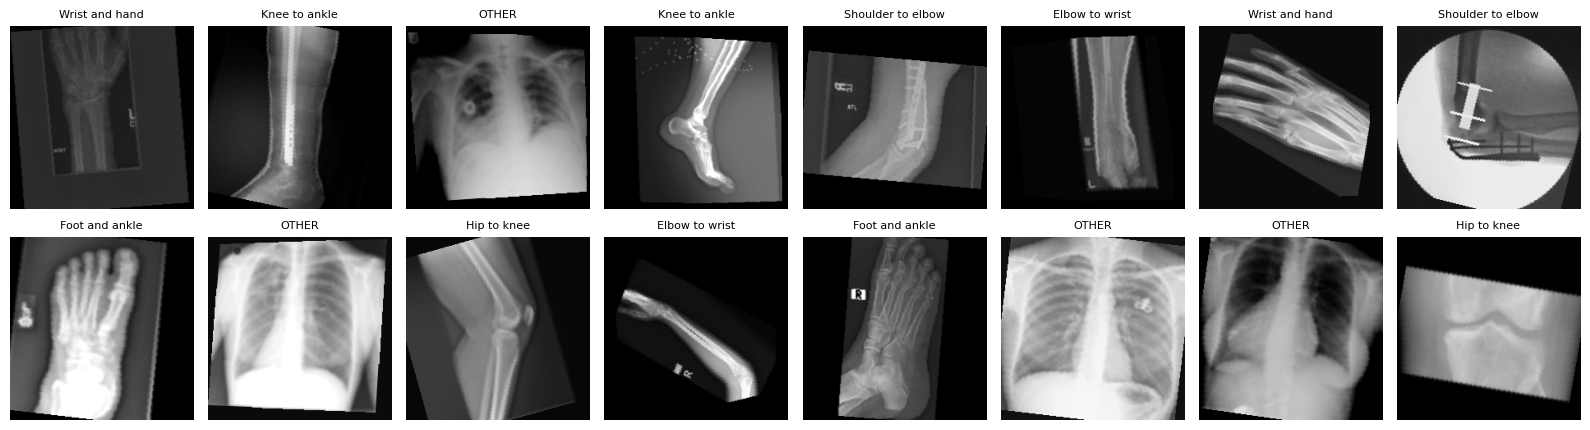

In [6]:
import matplotlib.pyplot as plt                       # look at augmented training images
loaders = make_loaders([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
xb, yb = next(iter(loaders['train']))
print('Groups in this batch:', pd.Series([SUPER[CLASSES[k]] for k in yb.tolist()]).value_counts().to_dict())
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, y in zip(axes.flat, xb[:16], yb[:16]):
    ax.imshow(img[0] * 0.229 + 0.485, cmap='gray', vmin=0, vmax=1); ax.set_title(SHORT[CLASSES[y]], fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

## Step 2 – Training (same loop as notebook 03, best epoch by validation macro-F1)

In [7]:
import torch.nn as nn, torch.nn.functional as F
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
from sklearn.metrics import f1_score

def build(name):
    if MODELS[name] == 'torchvision':
        m = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, len(CLASSES))
        return m, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    m = timm.create_model(MODELS[name], pretrained=True, num_classes=len(CLASSES))
    return m, list(m.pretrained_cfg['mean']), list(m.pretrained_cfg['std'])

def save_preds(name, split, p):
    out = splits[split][['path', 'filename', 'label', 'source', 'cache_idx']].copy()
    out[[f'p_{SHORT[c]}' for c in CLASSES]] = p; ps = p @ M
    out[[f'p_{s}' for s in SUPER_NAMES]] = ps
    out['pred_label'] = [CLASSES[k] for k in p.argmax(1)]
    out['true_super'] = out.label.map(SUPER); out['pred_super'] = [SUPER_NAMES[k] for k in ps.argmax(1)]
    out.to_csv(OUT_DIR / f'preds_{name}_{split}.csv', index=False)

def train_and_evaluate(name):
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    model, mean, std = build(name); model = model.to(device)
    loaders = make_loaders(mean, std)
    crit = nn.CrossEntropyLoss()                                   # balance comes from the sampler
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    scaler = torch.amp.GradScaler('cuda'); path = OUT_DIR / f'{name}_model2v2_best.pt'

    @torch.no_grad()
    def predict(loader):
        model.eval(); ps = []
        for xb, _ in loader:
            with torch.amp.autocast('cuda'):
                ps.append(F.softmax(model(xb.to(device)).float(), 1).cpu())
        return torch.cat(ps).numpy()

    best, best_ep, wait = -1, 0, 0
    for ep in range(1, EPOCHS + 1):
        t0 = time.time(); model.train(); tot = 0.0
        for xb, yb in loaders['train']:
            xb, yb = xb.to(device), yb.to(device); opt.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item() * len(yb)
        sched.step()
        p = predict(loaders['val']); y = splits['val'].y.values
        f1 = f1_score(y, p.argmax(1), average='macro')
        leg = splits['val'].label.map(SUPER).values == 'LEG'
        leg_acc = ((p @ M).argmax(1)[leg] == 1).mean()
        print(f'Epoch {ep:2d} | loss {tot/len(splits["train"]):.3f} | val acc {(p.argmax(1) == y).mean():.3f} '
              f'| val macro-F1 {f1:.3f} | val LEG correct {leg_acc:.3f} | {time.time()-t0:.0f}s')
        if f1 > best:
            best, best_ep, wait = f1, ep, 0
            torch.save({'state_dict': model.state_dict(), 'name': name, 'timm_name': MODELS[name], 'classes': CLASSES,
                        'super': SUPER, 'img_size': IMG_SIZE, 'mean': mean, 'std': std, 'epoch': ep}, path)
            print('   ✓ saved best model')
        else:
            wait += 1
            if wait >= PATIENCE: print('Early stopping.'); break

    model.load_state_dict(torch.load(path, map_location=device)['state_dict'])
    for s in ['val', 'test', 'newtest']: save_preds(name, s, predict(loaders[s]))
    info = {'model': name, 'best_epoch': best_ep, 'best_val_macro_f1': round(best, 4),
            'size_mb': round(os.path.getsize(path) / 1e6, 1)}
    json.dump(info, open(OUT_DIR / f'info_{name}.json', 'w')); print('Done:', info)
    del model; torch.cuda.empty_cache()

In [8]:
train_and_evaluate('mobilenetv3')

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 89.3MB/s]


Epoch  1 | loss 1.415 | val acc 0.676 | val macro-F1 0.566 | val LEG correct 0.882 | 20s
   ✓ saved best model
Epoch  2 | loss 0.764 | val acc 0.790 | val macro-F1 0.753 | val LEG correct 0.845 | 11s
   ✓ saved best model
Epoch  3 | loss 0.489 | val acc 0.880 | val macro-F1 0.857 | val LEG correct 0.919 | 12s
   ✓ saved best model
Epoch  4 | loss 0.407 | val acc 0.878 | val macro-F1 0.858 | val LEG correct 0.913 | 12s
   ✓ saved best model
Epoch  5 | loss 0.323 | val acc 0.888 | val macro-F1 0.874 | val LEG correct 0.925 | 13s
   ✓ saved best model
Epoch  6 | loss 0.319 | val acc 0.893 | val macro-F1 0.874 | val LEG correct 0.907 | 12s
Epoch  7 | loss 0.272 | val acc 0.898 | val macro-F1 0.880 | val LEG correct 0.894 | 12s
   ✓ saved best model
Epoch  8 | loss 0.233 | val acc 0.915 | val macro-F1 0.900 | val LEG correct 0.919 | 12s
   ✓ saved best model
Epoch  9 | loss 0.231 | val acc 0.924 | val macro-F1 0.913 | val LEG correct 0.932 | 12s
   ✓ saved best model
Epoch 10 | loss 0.208 |

In [9]:
train_and_evaluate('deit_small')

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch  1 | loss 0.819 | val acc 0.832 | val macro-F1 0.818 | val LEG correct 0.944 | 12s
   ✓ saved best model
Epoch  2 | loss 0.408 | val acc 0.847 | val macro-F1 0.825 | val LEG correct 0.981 | 12s
   ✓ saved best model
Epoch  3 | loss 0.294 | val acc 0.888 | val macro-F1 0.865 | val LEG correct 0.957 | 13s
   ✓ saved best model
Epoch  4 | loss 0.257 | val acc 0.893 | val macro-F1 0.875 | val LEG correct 0.950 | 12s
   ✓ saved best model
Epoch  5 | loss 0.227 | val acc 0.898 | val macro-F1 0.892 | val LEG correct 0.944 | 12s
   ✓ saved best model
Epoch  6 | loss 0.230 | val acc 0.920 | val macro-F1 0.908 | val LEG correct 0.950 | 12s
   ✓ saved best model
Epoch  7 | loss 0.176 | val acc 0.903 | val macro-F1 0.889 | val LEG correct 0.925 | 15s
Epoch  8 | loss 0.147 | val acc 0.917 | val macro-F1 0.906 | val LEG correct 0.975 | 19s
Epoch  9 | loss 0.126 | val acc 0.922 | val macro-F1 0.906 | val LEG correct 0.963 | 12s
Epoch 10 | loss 0.114 | val acc 0.914 | val macro-F1 0.894 | val LE

## Summary – Model 2 v2 training
Balanced sampling worked: training share HAND 0.4 / LEG 0.4 / OTHER 0.2 (first batch: LEG 27, HAND 23, OTHER 14);
before, LEG was ~17% of training images. New augmentations visible (metal-like shapes, strips, perspective).
MobileNetV3 v2: best epoch 11, val macro-F1 0.923, val LEG correct 95.7%.
DeiT-Small v2: best epoch 6 (early stop at 10), val macro-F1 0.908, val LEG correct 95.0%.
Validation now includes new LEG images, so values are not comparable with v1 – comparison in notebook 07.